## Імпорт бібліотек

In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns  

## Підготовка даних

In [3]:
wholesale_customer = pd.read_csv('Wholesale customers data.csv')

In [4]:
wholesale_customer.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [5]:
wholesale_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [6]:
X = wholesale_customer.iloc[:, [2,3]].values

## Побудова моделі

In [7]:
from sklearn.cluster import KMeans
clalist=[]

Визначаємо оптимальну кількість кластерів за допомогою метода ліктя

In [8]:
for i in range(1,11):
    kmeans = KMeans(n_clusters= i, init='k-means++', random_state=42)
    kmeans.fit(X)
    clalist.append(kmeans.inertia_)  

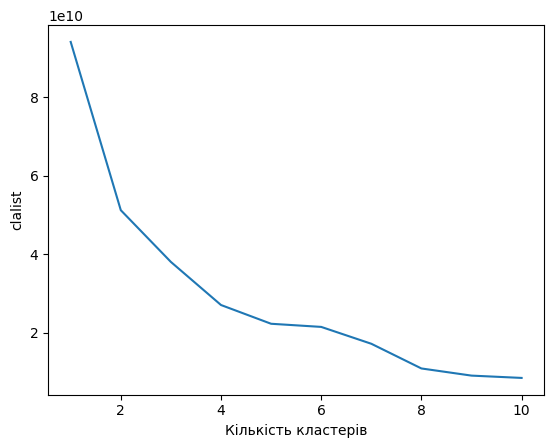

In [9]:
plt.plot(range(1,11), clalist)
plt.xlabel('Кількість кластерів')
plt.ylabel('clalist')
plt.show()

За допомогою графіка вибираємо кількість кластерів: 4

In [10]:
kmeansmodel = KMeans(n_clusters= 4, init='k-means++', random_state=42)
y_kmeans= kmeansmodel.fit_predict(X)

## Візуалізація кластеризації

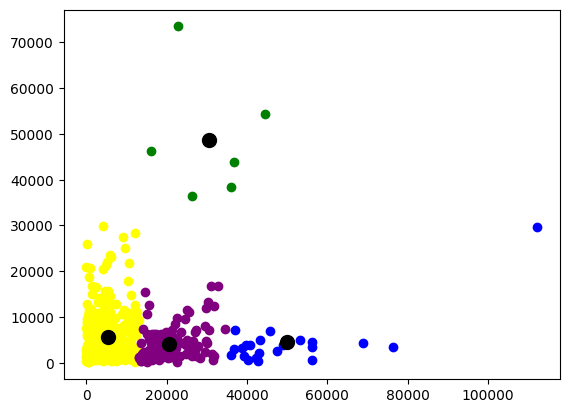

In [11]:
plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], c = 'yellow')
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], c = 'purple')
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], c = 'blue')
plt.scatter(X[y_kmeans == 3, 0], X[y_kmeans == 3, 1], c = 'green')
plt.scatter(kmeansmodel.cluster_centers_[:, 0], kmeansmodel.cluster_centers_[:, 1], s = 100, c = 'black')